# 04 · Feature engineering: the `customer_features` table and feature documentation

**Phase 2 deliverables:** the **customer_features table** that feeds the model and the dashboard, and the **feature documentation**.

| Step (from the plan) | Where |
|---|---|
| Build customer features with SQL views | `week2/5_feature_views.sql` STEP 1-6 (`feat.customer_features_ds`, plan column names) and `week2/6_...sql` (`feat.customer_features`, `feat.customer_outcomes`) |
| Impute missing budgets from the prices each customer viewed; fix budget typos | typos fixed in `week1/3_...sql` STEP 3; **imputation here** |
| Night-session share, virtual-tour share, agent response time | `feat.customer_features_ds` |
| Log-transform money, scale numeric features, drop features more than 0.8 correlated | **here** |
| Keep outcomes (converted, deal value, late payment) out of the model | outcomes stay in `feat.customer_outcomes`; checked below |

**Outputs**
* PostgreSQL table **`feat.customer_features_model`** (one row per customer: imputed features, flags and the scaled model inputs `z_*`)
* `features/customer_features.parquet` (the path the Phase 3 model code reads) and a copy in `reports/04_features/`
* `reports/04_features/Veltrix_feature_documentation.docx` and `feature_list.xlsx`

**Gate:** the feature list is reviewed by the business analysts for meaning (sign-off table at the end of the Word document).

In [1]:
# First time only:  %pip install sqlalchemy psycopg2-binary python-docx openpyxl pyarrow scikit-learn seaborn

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from IPython.display import display, Markdown
import vx

vx.connect()
vx.style()
OUT = vx.out_dir("04_features")
CH = OUT / "charts"
say = lambda s: display(Markdown(s))

Connected to database 'Veltrix' on localhost:5432 as postgres


## 1. Read the feature view (plan column names)

In [3]:
if not vx.exists("feat.customer_features_ds"):
    raise SystemExit("Run STEP 6 of week2/5_feature_views.sql first (creates feat.customer_features_ds).")
df = vx.Q("SELECT * FROM feat.customer_features_ds ORDER BY customer_id")
outcome_cols = vx.Q("""SELECT column_name FROM information_schema.columns
                       WHERE table_schema = 'feat' AND table_name = 'customer_outcomes'""").column_name.tolist()
leak = sorted(set(df.columns) & (set(outcome_cols) - {"customer_id"}))
assert not leak, f"Outcome columns found in the feature table: {leak}"
say(f"**{len(df):,} customers, {df.shape[1] - 1} columns.** No outcome column (conversion, deal value, payments) is in the feature table: "
    f"they stay in `feat.customer_outcomes` and are used only to validate the segments.")
df.head()

**100,573 customers, 29 columns.** No outcome column (conversion, deal value, payments) is in the feature table: they stay in `feat.customer_outcomes` and are used only to validate the segments.

,customer_id,budget_gbp,rent_budget_pcm_gbp,sessions_total,night_session_share,properties_viewed,virtual_tour_share,enquiries_total,days_since_last_activity,preferred_region,...,off_plan_share,london_share,saves_total,property_events_total,inbound_contacts_total,median_agent_response_min,median_viewed_price_gbp,n_sale_price_views,median_viewed_rent_pcm_gbp,n_rent_price_views
0,VLX-C00010000,NaN,NaN,26,0.000,128,0.021429,1,171,London,...,0.150000,0.714286,11,140,2,709.0,447500.0,140.0,NaN,0.0
1,VLX-C00010002,NaN,NaN,44,0.023,191,0.044025,0,930,South East,...,0.000000,0.075472,21,318,0,NaN,NaN,0.0,1350.0,318.0
2,VLX-C00010006,320000.0,NaN,33,0.030,177,0.017857,2,908,North West,...,0.169643,0.013393,25,224,5,500.0,300000.0,224.0,NaN,0.0
3,VLX-C00010008,NaN,4500.0,1,0.000,1,0.000000,0,469,London,...,0.000000,1.000000,0,1,0,NaN,NaN,0.0,4525.0,1.0
4,VLX-C00010009,190000.0,NaN,12,0.000,74,0.024096,2,1068,Yorkshire and the Humber,...,0.012048,0.024096,5,83,6,341.5,205000.0,83.0,NaN,0.0


## 2. Impute missing budgets from the prices each customer viewed
Rule (in order):
1. **Stated** budget (typos already fixed in SQL) is kept.
2. Blank, and the customer viewed **3+ priced listings** of that kind: use the **median price (or rent) viewed**.
3. Still blank: the median stated-or-viewed budget of customers with the **same intent, customer type and preferred region**.

Budgets only apply to the customer's intent: buyers have no rent budget and renters no purchase budget (those stay 0 in the model, as in the plan's code).

In [4]:
def impute(df, col, viewed, nviews, intent):
    is_t = df.primary_intent == intent
    out = df[col].astype(float).copy()
    src = pd.Series(np.where(out.notna(), "stated", ""), index=df.index, dtype=object)
    m2 = is_t & out.isna() & (df[nviews].fillna(0) >= 3) & df[viewed].notna()
    out[m2] = df.loc[m2, viewed].astype(float)
    src[m2] = "median viewed"
    grp = df.assign(v=out).loc[is_t].groupby(["customer_type", "preferred_region"]).v.median()
    m3 = is_t & out.isna()
    out[m3] = [grp.get((t, r), np.nan) for t, r in zip(df.loc[m3, "customer_type"], df.loc[m3, "preferred_region"])]
    out[m3 & out.isna()] = out[is_t].median()
    src[m3] = "group median"
    out[~is_t] = np.nan
    src[~is_t] = "not applicable"
    return out, src

df["budget_gbp_imputed"], df["budget_source"] = impute(df, "budget_gbp", "median_viewed_price_gbp", "n_sale_price_views", "Buy")
df["rent_budget_pcm_imputed"], df["rent_budget_source"] = impute(df, "rent_budget_pcm_gbp", "median_viewed_rent_pcm_gbp", "n_rent_price_views", "Rent")
src_tab = pd.concat([df[df.primary_intent == "Buy"].budget_source.value_counts().rename("Buyers: purchase budget"),
                     df[df.primary_intent == "Rent"].rent_budget_source.value_counts().rename("Renters: rent budget")], axis=1).fillna(0).astype(int)
display(src_tab)
buy = df[df.primary_intent == "Buy"]
chk = buy[buy.budget_source == "stated"]
chk = chk[(chk.n_sale_price_views >= 3) & chk.median_viewed_price_gbp.notna()]
ratio = (chk.median_viewed_price_gbp / chk.budget_gbp).median()
say(f"**Is 'median price viewed' a fair stand-in?** For buyers who state a budget and viewed 3+ priced listings, the median price they viewed is "
    f"**{ratio:.2f}x** their stated budget (1.00 = identical), so the imputation is close to what customers would have told us.")

,Buyers: purchase budget,Renters: rent budget
stated,49550,12876
median viewed,28273,7131
group median,1865,878


**Is 'median price viewed' a fair stand-in?** For buyers who state a budget and viewed 3+ priced listings, the median price they viewed is **0.96x** their stated budget (1.00 = identical), so the imputation is close to what customers would have told us.

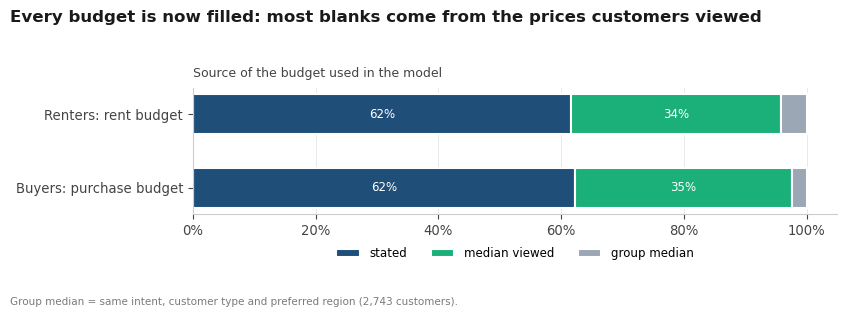

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 3.0))
pal = {"stated": vx.NAVY, "median viewed": vx.SERIES[2], "group median": vx.GREY}
for i, col in enumerate(src_tab.columns):
    left = 0
    tot = src_tab[col].sum()
    for k in ["stated", "median viewed", "group median"]:
        v = src_tab.loc[k, col] if k in src_tab.index else 0
        ax.barh(col, v / tot, left=left, color=pal[k], label=k if i == 0 else None, height=0.55, edgecolor="white", linewidth=1.5)
        if v / tot > 0.05:
            ax.text(left + v / tot / 2, i, f"{v / tot:.0%}", ha="center", va="center", color="white", fontsize=8.5)
        left += v / tot
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18))
ax.grid(axis="y", visible=False)
gm = src_tab.loc["group median"].sum() if "group median" in src_tab.index else 0
p_imp = vx.finish(fig, ax, "Every budget is now filled: most blanks come from the prices customers viewed",
                  "Source of the budget used in the model", CH / "01_budget_imputation.png",
                  note=f"Group median = same intent, customer type and preferred region ({gm:,} customers).")

## 3. Candidate numeric features, log-transform of money, and the 0.8 correlation rule

In [6]:
# Priority order: the plan's features first, then extra signals. When two features are more than
# 0.8 correlated, the one LATER in this list is dropped.
NUM_CANDIDATES = ["budget_gbp", "rent_budget_pcm_gbp", "sessions_total", "night_session_share", "properties_viewed",
                  "virtual_tour_share", "enquiries_total", "days_since_last_activity",
                  "mobile_share", "new_build_share", "london_share", "off_plan_share", "saves_total",
                  "property_events_total", "inbound_contacts_total"]
CAT = ["preferred_region", "preferred_property_type", "lead_source_primary", "finance_type", "customer_type", "is_overseas",
       "buyer_position", "age_band"]   # last two: extra signals beyond the plan's list (self-declared position; age separates downsizers)
MONEY = ["budget_gbp", "rent_budget_pcm_gbp"]

X = df[["customer_id"] + NUM_CANDIDATES + CAT].copy()
X["buyer_position"] = X.buyer_position.fillna("Not stated")
X["budget_gbp"] = df.budget_gbp_imputed
X["rent_budget_pcm_gbp"] = df.rent_budget_pcm_imputed
X[NUM_CANDIDATES] = X[NUM_CANDIDATES].astype(float)
X[MONEY] = np.log1p(X[MONEY].fillna(0))        # log of money; 0 where the budget does not apply
X["days_since_last_activity"] = X.days_since_last_activity.fillna(X.days_since_last_activity.median())
corr = X[NUM_CANDIDATES].corr()
keep, dropped = [], []
for f in NUM_CANDIDATES:
    # the two budgets are exempt from each other: every customer has exactly one of them (buyers vs renters),
    # so their -0.99 correlation only restates intent and dropping either would erase renters' (or buyers') price level
    hit = [k for k in keep if abs(corr.loc[f, k]) > 0.8 and not (f in MONEY and k in MONEY)]
    if hit:
        dropped.append(dict(feature=f, dropped_because=f"r = {corr.loc[f, hit[0]]:.2f} with {hit[0]}"))
    else:
        keep.append(f)
NUM = keep
display(pd.DataFrame(dropped))
print(f"Budget vs rent budget r = {corr.loc['budget_gbp', 'rent_budget_pcm_gbp']:.2f}: kept both (mutually exclusive by intent, see comment).")
say(f"**{len(NUM)} numeric features kept**, {len(dropped)} dropped for correlation above 0.8: "
    + "; ".join(f"`{d['feature']}` ({d['dropped_because']})" for d in dropped) + ".")

,feature,dropped_because
0,properties_viewed,r = 0.92 with sessions_total
1,off_plan_share,r = 0.83 with new_build_share
2,saves_total,r = 0.89 with sessions_total
3,property_events_total,r = 0.95 with sessions_total
4,inbound_contacts_total,r = 0.88 with enquiries_total


Budget vs rent budget r = -0.99: kept both (mutually exclusive by intent, see comment).


**10 numeric features kept**, 5 dropped for correlation above 0.8: `properties_viewed` (r = 0.92 with sessions_total); `off_plan_share` (r = 0.83 with new_build_share); `saves_total` (r = 0.89 with sessions_total); `property_events_total` (r = 0.95 with sessions_total); `inbound_contacts_total` (r = 0.88 with enquiries_total).

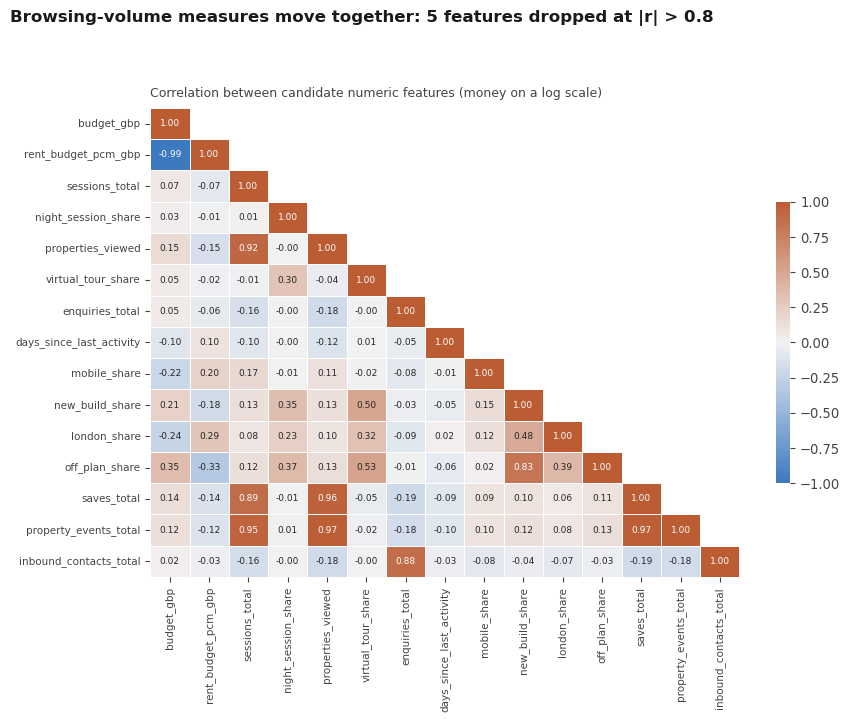

In [7]:
fig, ax = plt.subplots(figsize=(9, 7.2))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap=sns.diverging_palette(250, 25, s=80, l=50, as_cmap=True), vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 6.5}, linewidths=0.5, linecolor="white", cbar_kws={"shrink": 0.6}, ax=ax)
ax.tick_params(labelsize=7.5)
ax.grid(False)
p_corr = vx.finish(fig, ax, f"Browsing-volume measures move together: {len(dropped)} features dropped at |r| > 0.8",
                   "Correlation between candidate numeric features (money on a log scale)", CH / "02_correlation.png")

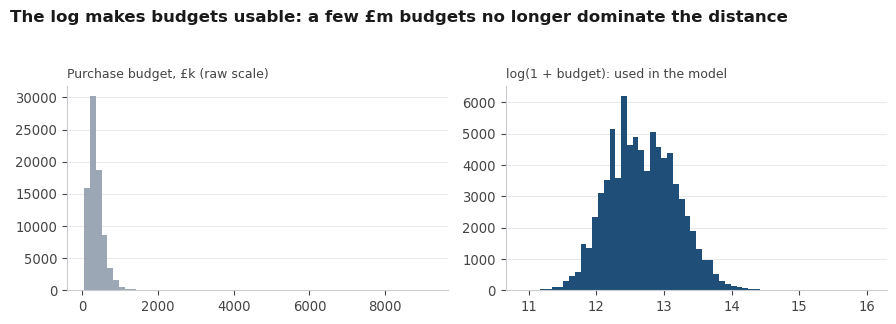

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
b = df.budget_gbp_imputed.dropna()
axes[0].hist(b / 1e3, bins=60, color=vx.GREY)
axes[0].set_title("Purchase budget, £k (raw scale)", loc="left", fontsize=9, color=vx.INK2)
axes[1].hist(np.log1p(b), bins=60, color=vx.NAVY)
axes[1].set_title("log(1 + budget): used in the model", loc="left", fontsize=9, color=vx.INK2)
for a in axes:
    a.grid(axis="x", visible=False)
p_log = vx.finish(fig, axes[0], "The log makes budgets usable: a few £m budgets no longer dominate the distance", "", CH / "03_log_budget.png")

## 4. Scale the numeric features and save the table

In [9]:
scaler = StandardScaler()
Z = pd.DataFrame(scaler.fit_transform(X[NUM]), columns=[f"z_{c}" for c in NUM], index=X.index)
model = pd.concat([df[["customer_id", "primary_intent", "budget_source", "rent_budget_source"]],
                   df[["budget_gbp_imputed", "rent_budget_pcm_imputed"]],
                   df[[c for c in NUM if c not in MONEY]].astype(float),
                   X[CAT].astype({"is_overseas": "bool"}), Z], axis=1)
model.columns = [c.lower() for c in model.columns]
vx.run("DROP TABLE IF EXISTS feat.customer_features_model CASCADE")
model.to_sql("customer_features_model", vx.ENGINE, schema="feat", index=False, chunksize=10000, method="multi")
vx.run("ALTER TABLE feat.customer_features_model ADD PRIMARY KEY (customer_id)")

(vx.ROOT / "features").mkdir(exist_ok=True)
plan_cols = df[["customer_id"]].join(X[NUM_CANDIDATES + CAT].drop(columns=MONEY)).assign(
    budget_gbp=df.budget_gbp_imputed, rent_budget_pcm_gbp=df.rent_budget_pcm_imputed, primary_intent=df.primary_intent)
plan_cols.to_parquet(vx.ROOT / "features" / "customer_features.parquet", index=False)
plan_cols.to_parquet(OUT / "customer_features.parquet", index=False)
model.to_parquet(OUT / "customer_features_model.parquet", index=False)
json.dump({"numeric": NUM, "categorical": CAT, "money_log1p": MONEY, "dropped_for_correlation": dropped,
           "scaler_mean": dict(zip(NUM, scaler.mean_.round(6))), "scaler_scale": dict(zip(NUM, scaler.scale_.round(6)))},
          open(OUT / "feature_spec.json", "w"), indent=2)
say(f"Saved **feat.customer_features_model** ({len(model):,} rows, {model.shape[1]} columns), "
    f"`features/customer_features.parquet` and `feature_spec.json` (the lists notebook 05 uses, and the scaler for monthly scoring).")

Saved **feat.customer_features_model** (100,573 rows, 32 columns), `features/customer_features.parquet` and `feature_spec.json` (the lists notebook 05 uses, and the scaler for monthly scoring).

## 5. Feature documentation

In [10]:
DOC = {   # feature: (definition, source)
    "budget_gbp": ("Purchase budget, £. Stated (typos fixed) or imputed; buyers only", "clean_customers + feat.customer_viewed_prices"),
    "rent_budget_pcm_gbp": ("Monthly rent budget, £. Stated (fixed) or imputed; renters only", "clean_customers + feat.customer_viewed_prices"),
    "sessions_total": ("Known (logged-in) web sessions", "clean_web_sessions"),
    "night_session_share": ("Share of sessions starting 00:00-05:59 UK time", "clean_web_sessions"),
    "properties_viewed": ("Distinct listings the customer interacted with", "clean_property_views"),
    "virtual_tour_share": ("Virtual tours / all property events", "clean_property_views"),
    "enquiries_total": ("Leads (enquiries) raised", "clean_leads"),
    "days_since_last_activity": ("Days from last session, lead or contact to 30 Sep 2026", "sessions, leads, interactions"),
    "mobile_share": ("Share of sessions on mobile", "clean_web_sessions"),
    "new_build_share": ("Share of property events on new-build listings", "clean_property_views + properties"),
    "london_share": ("Share of property events on London listings", "clean_property_views + locations"),
    "off_plan_share": ("Share of property events on off-plan listings", "clean_property_views + properties"),
    "saves_total": ("Listings saved", "clean_property_views"),
    "property_events_total": ("All property events (views, saves, tours, shares, floorplans)", "clean_property_views"),
    "inbound_contacts_total": ("Inbound contacts across all leads", "clean_interactions"),
    "preferred_region": ("Region viewed most (else home region)", "property views + locations"),
    "preferred_property_type": ("Property type viewed most", "property views + properties"),
    "lead_source_primary": ("Channel of most of the customer's leads; 'No lead' if none", "clean_leads"),
    "finance_type": ("Mortgage, cash, buy-to-let, shared ownership, renting, company let ...", "clean_customers"),
    "customer_type": ("Individual, Limited company (SPV), Corporate", "clean_customers"),
    "is_overseas": ("Lives outside the UK (residence, never IP)", "clean_customers"),
    "buyer_position": ("Self-declared position: first-time buyer, home mover, landlord, downsizer, renter ... or Not stated", "clean_customers"),
    "age_band": ("Age band; 'Unknown' when blank (kept as its own category)", "clean_customers"),
}
rows = []
for f in NUM_CANDIDATES + CAT:
    s = df[f] if f not in MONEY else (df.budget_gbp_imputed if f == "budget_gbp" else df.rent_budget_pcm_imputed)
    used = f in NUM or f in CAT
    why = "" if used else next(d["dropped_because"] for d in dropped if d["feature"] == f)
    if f in CAT:
        summ = f"{s.nunique()} values; top: {s.value_counts().index[0]}"
        transform = "category (matched / not matched)"
    else:
        s = s.astype(float)
        summ = f"median {s.median():,.2f}; p95 {s.quantile(.95):,.2f}" if s.max() <= 1 else f"median {s.median():,.0f}; p95 {s.quantile(.95):,.0f}"
        transform = ("log(1+x), then z-score" if f in MONEY else "z-score") if used else "-"
    miss = df[f].isna().mean() * 100 if f in df else 0
    rows.append(dict(feature=f, type="categorical" if f in CAT else "numeric", definition=DOC[f][0], source=DOC[f][1],
                     missing_pct=round(miss, 1), summary=summ, transform=transform,
                     in_model="yes" if used else f"no ({why})"))
fl = pd.DataFrame(rows)
fl.to_excel(OUT / "feature_list.xlsx", index=False)
fl[["feature", "type", "missing_pct", "transform", "in_model"]]

,feature,type,missing_pct,transform,in_model
0,budget_gbp,numeric,50.7,"log(1+x), then z-score",yes
1,rent_budget_pcm_gbp,numeric,87.2,"log(1+x), then z-score",yes
2,sessions_total,numeric,0.0,z-score,yes
3,night_session_share,numeric,0.0,z-score,yes
4,properties_viewed,numeric,0.0,-,no (r = 0.92 with sessions_total)
5,virtual_tour_share,numeric,0.0,z-score,yes
6,enquiries_total,numeric,0.0,z-score,yes
7,days_since_last_activity,numeric,0.0,z-score,yes
8,mobile_share,numeric,0.0,z-score,yes
9,new_build_share,numeric,0.0,z-score,yes


In [11]:
r = vx.Report("Feature documentation", "Phase 2 · Feature engineering",
              "feat.customer_features_model · features/customer_features.parquet · generated by notebooks/04_feature_engineering.ipynb")
r.h1("Summary")
r.kpis([(f"{len(df):,}", "customers, one row each"), (f"{len(NUM)}", "numeric features"), (f"{len(CAT)}", "categorical features"),
        (f"{len(dropped)}", "dropped (|r| > 0.8)")])
r.bullets([f"**One row per customer** ({len(df):,}) with behaviour only. Outcomes (conversion, deal value, late payment) are kept in "
           f"feat.customer_outcomes and used only to check the segments afterwards, so the model cannot learn them.",
           f"**Budgets are complete.** Typos were fixed in SQL; blanks were filled from the median price (or rent) the customer viewed, "
           f"then from a group median. For buyers who state a budget, the median price they viewed is {ratio:.2f}x their budget, so the stand-in is fair.",
           "**Money is log-transformed** and every numeric feature is scaled to mean 0 and standard deviation 1, so no feature dominates because of its units.",
           f"**Correlated features were removed:** " + "; ".join(f"{d['feature']} ({d['dropped_because']})" for d in dropped) + "."])
r.h1("Feature list")
show = fl[["feature", "type", "definition", "missing_pct", "transform", "in_model"]].rename(columns={
    "feature": "Feature", "type": "Type", "definition": "Definition", "missing_pct": "% blank before", "transform": "Transform", "in_model": "In model"})
r.table(show, font=7.5, widths_cm=[3.4, 1.8, 5.2, 1.6, 2.4, 2.6])
r.h2("Sources and summary values")
r.table(fl[["feature", "source", "summary"]].rename(columns={"feature": "Feature", "source": "Built from", "summary": "Summary"}),
        font=7.5, widths_cm=[3.8, 6.2, 7])
r.h1("Budget imputation")
r.image(p_imp, "Where each budget used in the model comes from")
r.table(src_tab.reset_index().rename(columns={"index": "Budget source"}), widths_cm=[5, 5, 5])
r.h1("Transformations")
r.image(p_log, "Purchase budget before and after the log transform")
r.image(p_corr, "Correlation between candidate numeric features")
r.h1("Where the features live")
r.table(pd.DataFrame([
    ["feat.customer_features_ds", "Materialized view (SQL file 5, STEP 6)", "Features with the plan's names, before imputation"],
    ["feat.customer_features", "Table (SQL file 6)", "DA feature table used by the dashboard"],
    ["feat.customer_outcomes", "Table (SQL file 6)", "Outcomes, kept out of the model"],
    ["feat.customer_features_model", "Table (this notebook)", "Imputed features, flags and scaled z_ inputs"],
    ["features/customer_features.parquet", "File (this notebook)", "Input for the DS model code (DuckDB / pandas)"],
    ["reports/04_features/feature_spec.json", "File (this notebook)", "Feature lists and scaler, reused for monthly scoring"]],
    columns=["Object", "Kind", "Holds"]), widths_cm=[5.5, 4.5, 7])
r.h1("Gate: business analyst review")
r.p("Each feature must mean something a salesperson or marketer recognises. Reviewers tick each line or add a comment.")
r.table(pd.DataFrame({"Feature": NUM + CAT, "Meaningful? (Y/N)": "", "Comment": ""}), font=8, widths_cm=[5, 3, 9])
r.table(pd.DataFrame([["Business analyst", "", ""], ["Data scientist", "", ""], ["Data analyst", "", ""]],
                     columns=["Role", "Name", "Date signed"]), widths_cm=[5, 7, 5])
r.save(OUT / "Veltrix_feature_documentation.docx")

Saved reports\04_features\Veltrix_feature_documentation.docx
